# Clustering with Outlier Removal Implementation

In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

## Utility functions

COR Utilities

In [127]:
def generate_basic_partitions(X:pd.DataFrame, r:int, k_min:int = 2, k_max: int= None,seed:int = None)-> list[np.ndarray]:
    """
    Runs K-means on a data matrix to generate r basic partitions with variable number of clusters each. 
    Inputs:
    -   X: the data matrix;
    -   r: the number of basic partitions; 
    -   k_min: the minimum number of clusters in each partition. 2 by default;
    -   k_max: the maximum number of clusters that may compone each partition. No default value is provided;
    Outputs:
        The r partitions, in the form of a list of length r
    """
    if k_max is None:
        k_max = k_min**2
    elif k_max <k_min:
        print("Autofix - basic_partitioning: k_min greater than k_max; set to square.")
        k_max = k_min**2

    X = np.asarray(X,dtype = float)    
    basic_partitions = []
    np.random.seed(seed)
    for i in range(r):
        Kmeans_model = KMeans(n_clusters=np.random.randint(k_min,k_max+1), random_state=i, n_init=10)
        partition = Kmeans_model.fit_predict(X)
        basic_partitions.append(partition)
    return basic_partitions


def build_binary_matrices(partitions: list[np.ndarray])-> tuple[np.ndarray, np.ndarray]:
    """
    Constructs the binary matrices B and its complement, mapping observations from the original matrix and assigning 1 
    to the cell [l,ij] if, w.r.t. partition i, observation l belongs to cluster j.
    Input:
        The list of partitions.
    Output:
        Both matrix B and its complement.
    """
    cols = []
    for partition in partitions:
        for label in np.unique(partition):
            cols.append((partition ==label).astype(float))
    B = np.array(cols).T
    return B, 1-B

def generate_centroids(BB: list[np.ndarray], K: int)-> list[np.ndarray]:
    """
    Produces K centroids for the binary matrix BB, randomly variating the dimensions.
    Inputs:
    -   BB: the concatenated binary matrix
    -   K: the number of centroids (and clusters)
    Output:
        A list of K centroids randomly taken from BB with slightly varied values. 
    """
    if (K > BB.shape[0]):
        print("Numerical error: too much more clusters than observations. Cannot initialize centroids")
    return np.random.uniform(0,1, size = (K,BB.shape[1]))

def compute_kl_distances(BB: np.ndarray, centroids: np.ndarray, return_matrix:bool= False) -> tuple[np.ndarray,np.ndarray]| tuple[np.ndarray,np.ndarray,np.ndarray]:
    """
    Computes the KL distances between all points of the matrix and the centroids. 
    Note that the we are working on the original formula is: D_KL(P(x)||Q(x)) = sum_P(x) log (P(x)/Q(x))
    and since b can be either 0 or 1, we have that:
    -   the limit for x->0 of xlog(x/m) is 0,
    -   1log(1/m) = - log(m),
    we directly compute the result as: - BB * log (m).
    Inputs:
    -   BB: the concatenated binary matrix 
    -   centroids: the vector of K centroids 
    -   return_matrix: whether the whole matrix should be returned or not
    Outputs: 
    -   the n x K matrix of distances, if 'return_matrix' is set to True
    -   the label of the cluster of the closest centroid
    -   the distance from the closest centroid
    """
    m = np.clip(centroids, 1e-12, None)
    distances = -(BB @ np.log2(m).T)
    if return_matrix:
        return distances, distances.argmin(axis=1), distances.min(axis = 1)
    return distances.argmin(axis=1), distances.min(axis = 1)

def extract_outliers(distances_vector: np.ndarray, how_many_o:int) ->np.ndarray:
    """
    Looks for the top 'how_many_o' values having the highest distance in the distance vector and provides
    their indexes.
    Inputs:
    -   the distance vector
    -   how_many_o: the number of outliers we are looking for
    Output:
        The vector of indexes of the outlier candidates.
    """
    if (how_many_o<= 0):
        return np.array([], dtype=int)
    return np.argsort(distances_vector)[-how_many_o:]

def update_centroids(BB:np.ndarray, labels: np.ndarray, old_centroids: np.ndarray) -> np.ndarray:
    """
    """
    centroids = old_centroids.copy()
    for k in range(len(old_centroids)):
        cluster = BB[labels == k]
        if(len(cluster) > 0):
            centroids[k] = cluster.mean(axis = 0)
    return centroids

def compute_holoentropy(BB: np.ndarray,labels, centroids: np.ndarray) -> float: #non sono sicuro sia corretta#
    """
    """
    result = 0
    for k in range(len(centroids)):
        C_k = BB[labels == k] 
        if len(C_k) == 0:
            continue
        p = C_k.mean(axis= 0) 
        p = p[p > 0]   
        result += - len(C_k)* (p * np.log2(p)).sum() 
    return result

Datasets Utilities

In [113]:
def normalise_numeric(df: pd.DataFrame)-> pd.DataFrame:
    for col in df.columns:
        if df[col].dtype.kind not in "iuf":
            print("Dataset is not fully numeric. Force quitted.")
            return

    min = df.min(axis = 0)
    max = df.max(axis = 0)
    range = (max - min).replace(0,1)
    return (df - min)/(range)

def plot_target_differences(target:np.ndarray, labels:np.ndarray):
    plt.figure(figsize=(75,20))
    plt.scatter(np.arange(0,len(target)), target-labels)
    plt.plot(np.arange(0,len(target)), np.zeros(len(target)), color = "green", lw = 5)
    plt.show()

def PCA_scatter_plot(df: pd.DataFrame, labels: np.ndarray):
    p = PCA(2).fit_transform(df)
    inliers_mask = labels>=0
    plt.figure(figsize=(10,10))
    plt.scatter(p[inliers_mask,0], p[inliers_mask,1], c = labels[inliers_mask], cmap = "tab10", s = 33, alpha = 0.6)
    plt.scatter(p[labels ==-1, 0], p[labels ==-1, 1], marker = "x", c = "black", s = 20, label = "outliers found by COR")
    # plt.scatter(p[true_outliers, 0], p[true_outliers, 1], facecolors="none", edgecolors="red",
    #               s=70, label="real outliers")
    plt.legend()

COR

In [128]:
def COR(X: pd.DataFrame, K: int, o:int, r:int)-> tuple[np.ndarray, float, dict] | dict:
    """
    Main function; runs the COR algorithm as presented in the paper.
    """
    basic_partitions_labels = generate_basic_partitions(X, r, k_max=2*K)
    B, tilde_B = build_binary_matrices(basic_partitions_labels)
    BB = np.hstack([B,tilde_B])
    centroids = generate_centroids(BB, K)
    prev_obj_value = np.inf

    run_statistics = {
        "n_iterations" : 0,
        "prev_values": list([]), 
    }
    iter = 0
    while (iter<1000): 
        c_labels, min_distances= compute_kl_distances(BB, centroids= centroids)
        outlier_candidates = extract_outliers(min_distances, o) 
        c_labels[outlier_candidates] = -1
        centroids = update_centroids(BB, c_labels,centroids)
        obj_value = compute_holoentropy(BB, c_labels, centroids)

        if(prev_obj_value < obj_value):
            print("Objective value increased: force-quitted.")

            break
        elif (prev_obj_value-obj_value<= 1e-10): #the while cycle terminates once the marginal difference gets too small
            break

        run_statistics["prev_values"].append(prev_obj_value)
        print(f"iteration: {iter}; objective value: {obj_value}\n")
        prev_obj_value = obj_value
        iter+= 1
    run_statistics["n_iterations"] = iter
    return c_labels, obj_value, run_statistics

## Datasets

Wine 

iteration: 0; objective value: 543865.5644484137

iteration: 1; objective value: 464127.6554422921

iteration: 2; objective value: 430381.76868925476

iteration: 3; objective value: 417650.7730531123

iteration: 4; objective value: 390959.82167888543

iteration: 5; objective value: 387076.5700394657

iteration: 6; objective value: 387048.79800934385

target: 4215, labels: 4240. Difference: -25. Iters: 7


array([2, 2, 2, ..., 0, 0, 3], shape=(1599,))

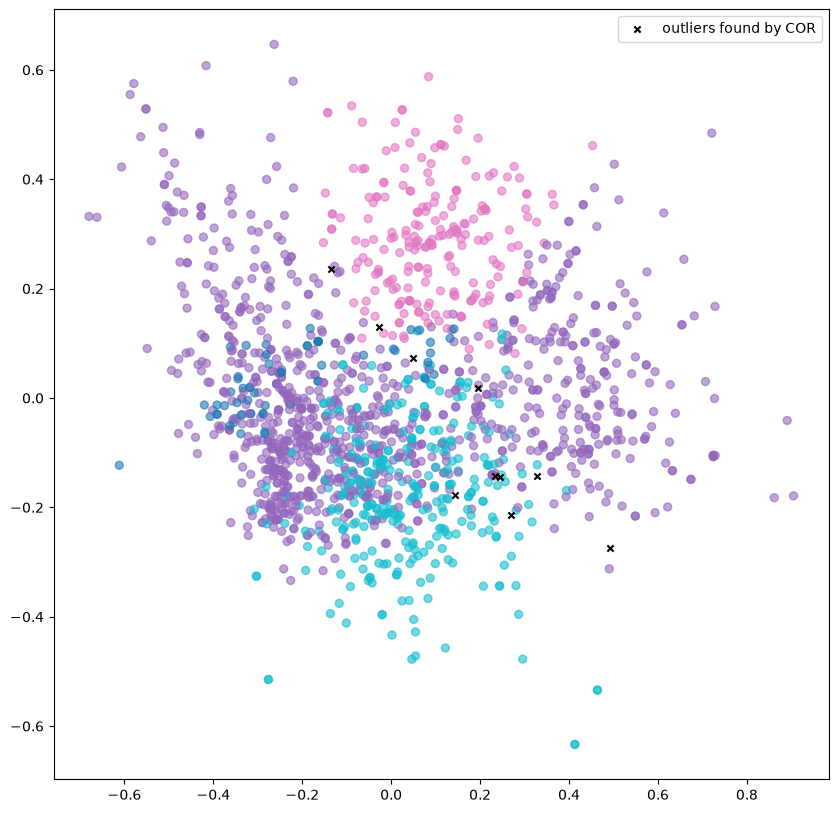

In [129]:
red_wine_quality = pd.read_csv("datasets/wine+quality/winequality-red.csv",delimiter=";")

target = red_wine_quality["quality"].to_numpy()
red_wine_quality.drop("quality",axis=1, inplace=True)
target = target - min(target)

red_wine_quality = normalise_numeric(red_wine_quality)
labels, obj, stats = COR(red_wine_quality,len(np.unique(target)),10, 100)

print(f"target: {sum(target)}, labels: {sum(labels)}. Difference: {sum(target-labels)}. Iters: {stats["n_iterations"]}")

PCA_scatter_plot(red_wine_quality, labels)
labels

iteration: 0; objective value: 3671424.044199203

iteration: 1; objective value: 3535784.76964254

iteration: 2; objective value: 3487869.8883110792

iteration: 3; objective value: 3460574.3005601633

iteration: 4; objective value: 3439248.78084638

iteration: 5; objective value: 3417998.13267049

iteration: 6; objective value: 3406766.0297028143

iteration: 7; objective value: 3399333.599283178

iteration: 8; objective value: 3389702.3458391717

iteration: 9; objective value: 3340386.331337624

iteration: 10; objective value: 3328502.376194401

iteration: 11; objective value: 3326768.4151296834

iteration: 12; objective value: 3326239.6172814453

iteration: 13; objective value: 3324474.4516926194

iteration: 14; objective value: 3262618.637123176

iteration: 15; objective value: 3214697.4272013707

iteration: 16; objective value: 3150390.1236029225

iteration: 17; objective value: 2939466.7052920233

iteration: 18; objective value: 2918423.3125269497

iteration: 19; objective value: 2

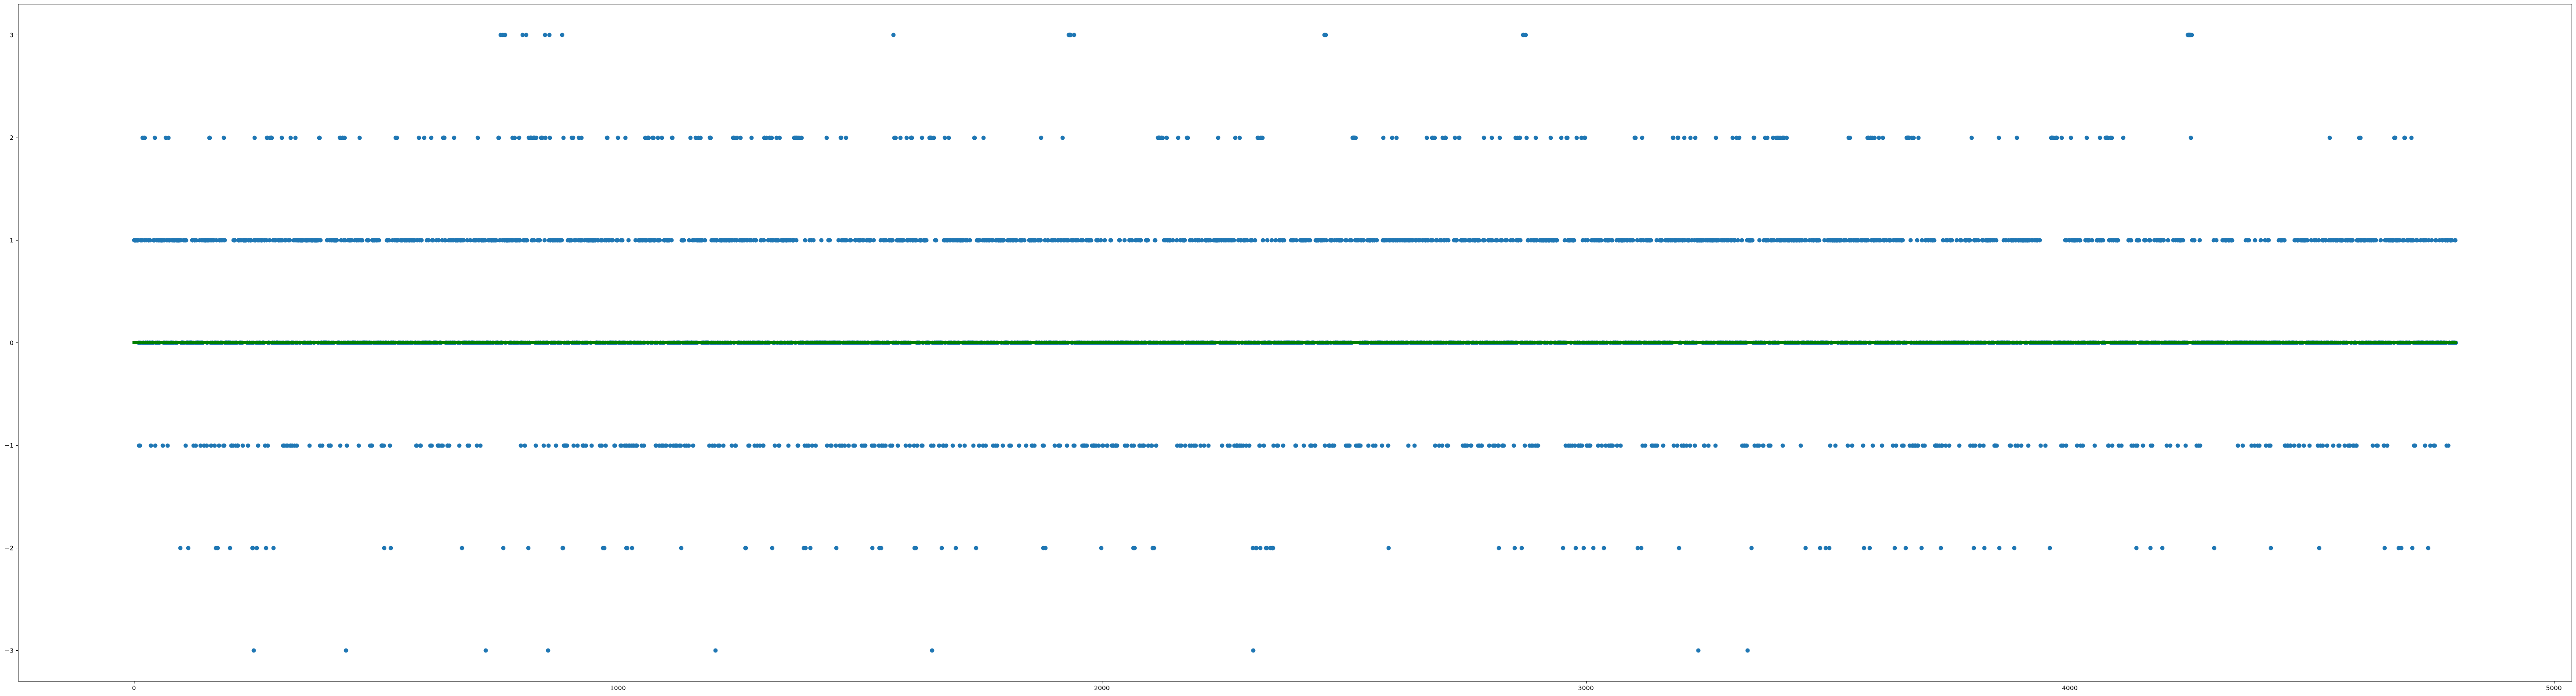

In [131]:
white_wine_quality = pd.read_csv("datasets/wine+quality/winequality-white.csv",delimiter=";")

target = white_wine_quality["quality"].to_numpy()
white_wine_quality.drop("quality",axis = 1, inplace = True)

target  = target - min(target)
white_wine_quality = normalise_numeric(white_wine_quality)

labels, obj, stats = COR(white_wine_quality,len(np.unique(target)),100, 200)
inliers_mask = labels != -1


print(white_wine_quality.shape)

print(f"target: {sum(target[inliers_mask])}, labels: {sum(labels[inliers_mask])}. Difference: {sum(target[labels!=-1]-labels[labels!=-1])}. Iters: {stats["n_iterations"]}")

plot_target_differences(target = target[inliers_mask], labels = labels[inliers_mask])


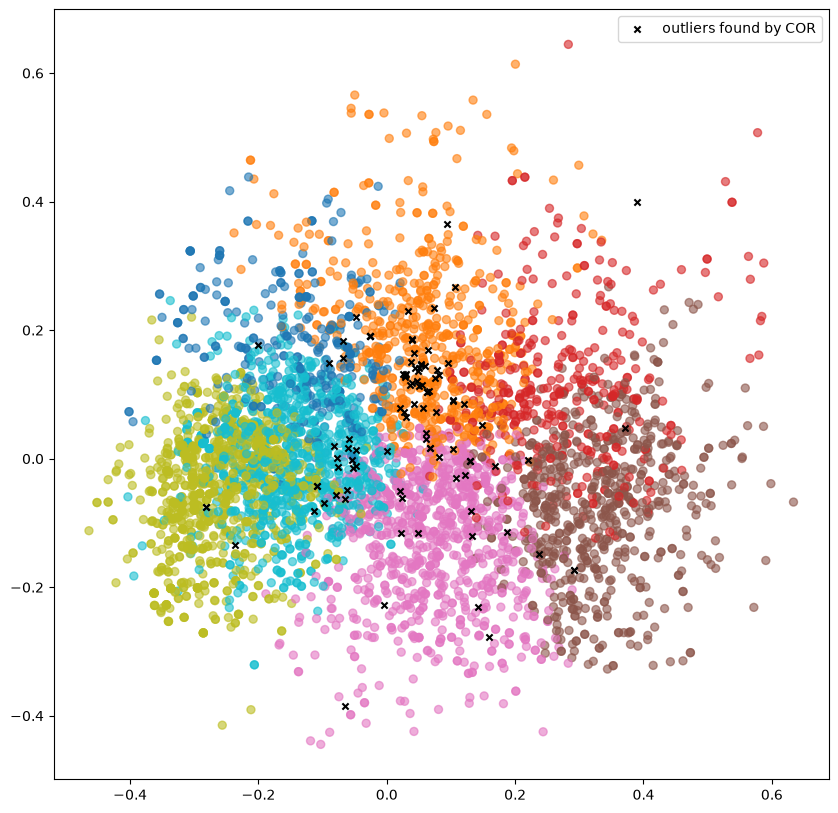

In [85]:
PCA_scatter_plot(white_wine_quality)

Forestfires

iteration: 0; objective value: 144884.85827989926

iteration: 1; objective value: 95938.36190587687

iteration: 2; objective value: 94077.86544179785



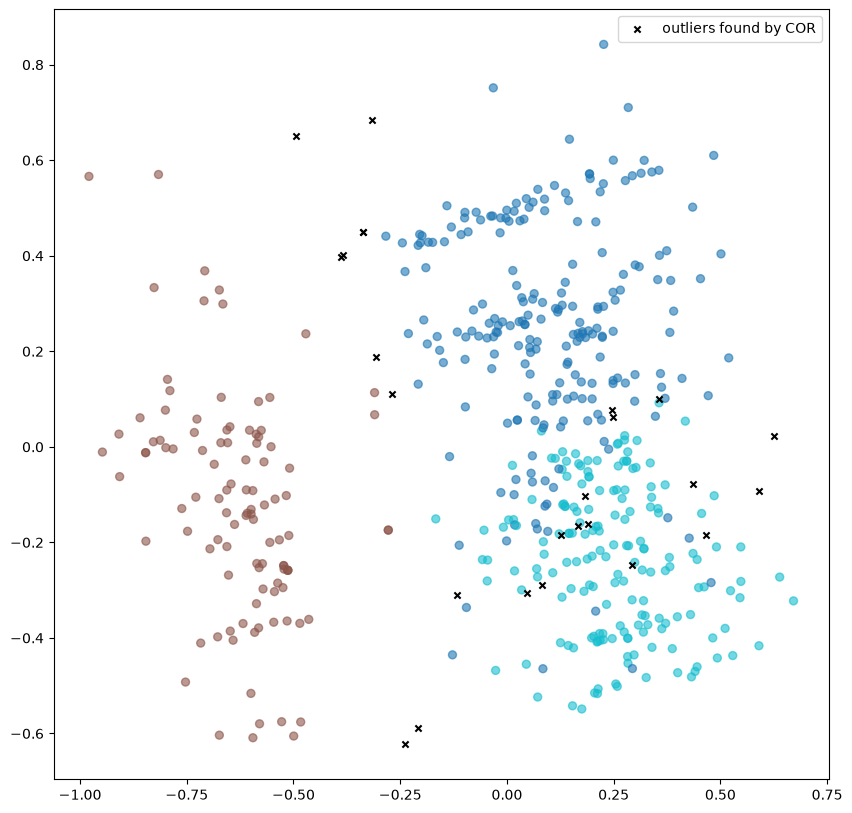

In [118]:
fires = pd.read_csv("datasets/forestfires.csv")
fires.head()
fires.drop(columns = ["day", "month"], inplace=True)
fires.head()
fires = normalise_numeric(fires)

labels,obj, stats = COR(fires, 3, int(len(fires)*0.05), 200)

PCA_scatter_plot(fires, labels)

## Performances